In [55]:
import plotly.io as pio
pio.renderers.default = 'notebook'

In [56]:
import pandas as pd
import numpy as np
from sklearn import datasets
import plotly.express as px
import plotly.graph_objs as go
from dash import Dash, dcc, html, Input, Output, State
from plotly.subplots import make_subplots

# <center> Метод опорных векторов </center>

In [57]:
iris = datasets.load_iris()

In [58]:
print(iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

    :Number of Instances: 150 (50 in each of three classes)
    :Number of Attributes: 4 numeric, predictive attributes and the class
    :Attribute Information:
        - sepal length in cm
        - sepal width in cm
        - petal length in cm
        - petal width in cm
        - class:
                - Iris-Setosa
                - Iris-Versicolour
                - Iris-Virginica
                
    :Summary Statistics:

    ============== ==== ==== ======= ===== ====================
                    Min  Max   Mean    SD   Class Correlation
    ============== ==== ==== ======= ===== ====================
    sepal length:   4.3  7.9   5.84   0.83    0.7826
    sepal width:    2.0  4.4   3.05   0.43   -0.4194
    petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
    petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
    ============== ==== ==== ======= ===== ===========

In [59]:
df = pd.DataFrame(iris.data, columns = iris.feature_names)

In [60]:
df['target'] = [1 if x==0 else -1 for x in iris.target]

In [61]:
app = Dash(__name__)


app.layout = html.Div([
    html.H4('Интерактивная диаграмма рассеяния'),
    html.P('Признак 1:'),
    dcc.Dropdown(df.columns, df.columns[0], id='dropdown_value_1'),
    dcc.Dropdown(df.columns, df.columns[1], id='dropdown_value_2'),
    dcc.Graph(id="graph"),
      
])


@app.callback(
    Output("graph", "figure"), 
    [Input("dropdown_value_1", "value"),
     Input("dropdown_value_2", "value")])
def display_hist(dropdown_value_1, dropdown_value_2):
    fig = px.scatter(df, x = dropdown_value_1, y = dropdown_value_2, color = 'target')
    return fig

# app.run(debug=True)

## Задача бинарной классификации

`Дано:` 
- множество объектов обучающей выборки $X^l = (x_i, y_i)_{i=1}^{l}, x_i\in \mathbb{R}$, разделенных на классы $Y=\{-1,1\}$; 
- множество объектов тестовой выборки, классовая принадлежность которых не известна. 


### 1. Линейная модель

Обучающая выборка $X^l = (x_i, y_i)_{i=1}^{l}, \quad x_i\in \mathbb{R}^n, \quad y_i \in \{-1, 1\}$

1. Модель классификации -- *линейная* с параметром $w\in \mathbb{R}^n$:

$$a(x,w, w_0 ) = sign (\langle x, w \rangle - w_0) = sign (-w_0 + \sum_{j=1}^n w_j f_j(x))$$

2. Функция потерь -- *бинарная* или ее аппроксимация:

$$\mathcal{L}(w, w_0, x) = [a(x,w, w_0)y  (x)<0] = [(\langle x, w \rangle - w_0) y(x) < 0] \leq L((\langle x, w \rangle -w_0) y(x))$$

3. Метод обучения -- *минимизация эмпирического риска*:

$$Q(w) = \sum_{i=1}^l\mathcal{L}(w,w_0,x_i) = \sum_{i=1}^l[(\langle x_i, w \rangle -w_0) y_i < 0] \leq \sum_{i=1}^lL((\langle x_i, w \rangle - w_0) y_i) \rightarrow \underset{w, w_0}{min}$$

4. Проверка на тестовой выборке $X^k = (\tilde{x_i}, \tilde{y_i})_{i=1}^k$:

$$\tilde{Q}(w) = \frac{1}{k}\sum_{i=1}^l[(\langle x_i, w \rangle-w_0) y_i < 0] $$

### Метод опорных векторов

Бинарный классификатор: $a(x,w ) = sign\,\mathit{g}(x, w), \quad Y\in\{-1, 1\}$

- $g(x,w)$ -- *разделяющая (дискриминантная) функция*
- $x: g(x,w) =0 $ -- разделяющая гиперплоскость между классами
- $M_i(w) = g(x_i, w)y_i$ -- отступ объекта $x_i$ от разделяющей поверхности, если $M_i(w)<0 \Leftrightarrow$ алгоритм $a(x,w)$ ошибается на $x_i$;

$$Q(w) = \sum_{i=1}^l\mathcal{L}(w,w_0,x_i) = \sum_{i=1}^l[(\langle x_i, w \rangle -w_0) y_i < 0] \leq$$
$$ \leq \sum_{i=1}^l[M_i(w,w_0)<0] \leq \sum_{i=1}^l(1-M_i(w,w_0))_+ + \frac{1}{2C}||w||^2 \rightarrow \underset{w, w_0}{min}$$

In [62]:
import math

In [63]:
x = np.array(np.arange(-3, 3, 0.01))
y_1 = [1 if x <
       0 else 0 for x in x]
y_2 = [math.log(i, 2) for i in 1. + np.exp(-x)]
y_3 = [ 1 - i if i < 1 else 0 for i in x]
fig = go.Figure(data = [go.Scatter(x= x, y = y_1, name = 'Пороговая функция потерь'), 
                        go.Scatter(x= x, y = y_2, name = 'Логарифмическая функция потерь'),
                        go.Scatter(x= x, y = y_3, name = 'Кусочно-линейная функция потерь')],
                layout = {'title' : 'Аппроксимация пороговой функции потерь'})
fig.show()

## Решение из коробки

### Построение модели

In [64]:
from sklearn import svm
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import train_test_split
##https://scikit-learn.org/stable/modules/calibration.html

In [65]:
X_train, X_test, y_train, y_test = train_test_split(
    df[['sepal length (cm)', 'sepal width (cm)']], 
    df['target'], test_size=0.33, random_state=42)

In [66]:
svm_model = svm.LinearSVC(penalty = 'l2', random_state = 0, dual = False)

In [67]:
model = CalibratedClassifierCV(svm_model) 

$$P(y=1|x)=\frac{1}{1+\exp(Af(x)+B)}$$

In [68]:
model.fit(X_train, y_train)

CalibratedClassifierCV(estimator=LinearSVC(dual=False, random_state=0))

In [69]:
predicted = model.predict(X_train)
predicted

array([-1, -1, -1,  1, -1, -1,  1,  1,  1, -1, -1,  1,  1,  1, -1,  1, -1,
       -1,  1, -1, -1,  1, -1, -1, -1, -1, -1, -1,  1, -1, -1,  1,  1, -1,
       -1,  1, -1,  1,  1, -1, -1, -1, -1, -1, -1, -1,  1,  1, -1, -1,  1,
        1,  1, -1, -1,  1, -1, -1,  1, -1, -1, -1, -1, -1,  1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1,  1, -1, -1, -1,  1, -1, -1, -1,  1, -1,  1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1,  1, -1, -1,  1, -1, -1],
      dtype=int64)

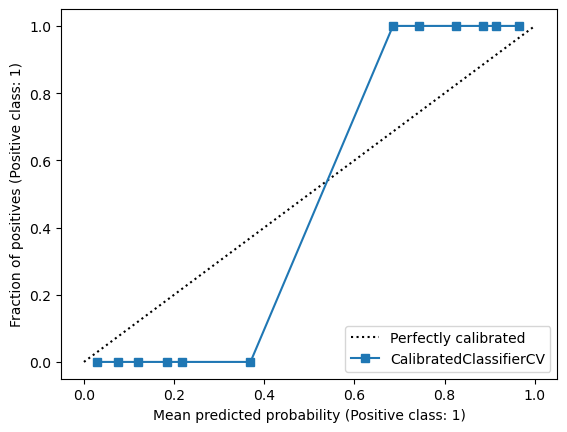

In [70]:
from sklearn.calibration import CalibrationDisplay

CalibrationDisplay.from_estimator(
    model,
    X_test,
    y_test,
    n_bins=20
)

### Оценка качества модели

In [71]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.metrics import RocCurveDisplay, roc_curve, roc_auc_score, auc

In [72]:
cm = confusion_matrix(y_train, predicted, labels=model.classes_)
pd.DataFrame(cm, index=model.classes_, columns=model.classes_)

,-1,1
-1,69,0
1,1,30


In [73]:
accuracy_score(y_train, predicted)

0.99

In [74]:
precision_score(y_train, predicted)

1.0

In [75]:
recall_score(y_train, predicted)

0.967741935483871

In [76]:
f1_score(y_train, predicted)

0.9836065573770492

In [77]:
print(classification_report(y_train, predicted, labels = model.classes_))

              precision    recall  f1-score   support

          -1       0.99      1.00      0.99        69
           1       1.00      0.97      0.98        31

    accuracy                           0.99       100
   macro avg       0.99      0.98      0.99       100
weighted avg       0.99      0.99      0.99       100



In [78]:
probabilities = model.predict_proba(X_train)[:,1]

In [79]:
fpr, tpr, th = roc_curve(y_train, probabilities)

In [80]:
fig = px.area(x = fpr, y = tpr, 
       labels = {
           'x':'False positive rate',
           'y': 'True positive rate'
                })
fig.add_trace(go.Scatter(x = [0,1], y=[0,1], marker_color = 'grey'))

### Визуализация

In [81]:
trained_classifiers = model.calibrated_classifiers_
classifier = trained_classifiers[0].estimator

In [82]:
h = 0.02
x_min, x_max = X_train.iloc[:, 0].min() - 1, X_train.iloc[:, 0].max() + 1
y_min, y_max = X_train.iloc[:, 1].min() - 1, X_train.iloc[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

In [83]:
test_df = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns = model.feature_names_in_)
test_df.head(1)

,sepal length (cm),sepal width (cm)
0,3.3,1.0


In [84]:
Z = model.predict(test_df)
Z = Z.reshape(xx.shape)

In [85]:
fig = go.Figure(go.Contour(
    z = classifier.decision_function(test_df), 
    x = test_df['sepal length (cm)'], 
    y = test_df['sepal width (cm)'],
    colorscale='RdYlGn',
    line_width=2,
    contours=dict(
        start = -1, 
        end = 1,
        size = 1,
        coloring ='lines',
        showlabels = True, # show labels on contours
        labelfont = dict( # label font properties
            size = 12,
            color = 'Black',
            )
        )))

In [86]:
support_vectors = np.where(np.abs(classifier.decision_function(X_train)) <= 1 + 1e-15)

In [87]:
fig.add_trace(go.Scatter(
    x = X_train['sepal length (cm)'], 
    y = X_train['sepal width (cm)'],
    mode = 'markers',
    marker=dict(size=10,
                color=y_train,
                colorscale='RdYlGn',
                line=dict(width=1, color = 'Black')),
    showlegend  = False
))
fig.add_trace(go.Scatter(
    x = X_train.iloc[support_vectors]['sepal length (cm)'],
    y = X_train.iloc[support_vectors]['sepal width (cm)'],
    mode = 'markers',
    marker=dict(size=20,
                color=y_train.iloc[support_vectors],
                colorscale='RdYlGn',
                #opacity = 0.5,
                line=dict(width=1),
                symbol=[114]
               ),
    showlegend = False))

**Задание**: 
1.  разобраться как работает method = 'isotonic' внутри CalibratedClassifierCV.
2.  понять, как считается и что такое оценка Брайера (Brier score)
3.  построить модель откалиброванную с помощью метода 'isotonic', вывести на одном рисунке кривые калибровки и посчитать для каждого варианты метрику Брайера.

#### Как работает method = 'isotonic' внутри CalibratedClassifierCV
isotonic калибрует вероятности модели с помощью изотонической регрессии.
1. Базовая модель предсказывает вероятности.
2. На отдельной калибровочной выборке сравниваются предсказанные вероятности с реальными метками классов.
3. Строится монотонная функция, которая преобразует исходные вероятности в более точные. 

В отличие от sigmoid, метод isotonic не предполагает конкретную форму функции, поэтому он гибче, но требует больше данных для обучения

#### Как считается и что такое оценка Брайера (Brier score)
Brier score - метрика, которая оценивает точность предсказанных моделью вероятностей. Чем меньше значение, тем лучше; идеальное значение - 0.
Для бинарной классификации формула:
$$
BS = \frac{1}{N}\sum_{i=1}^{N}(p_i-y_i)^2
$$
Где:
- $N$ — количество объектов;
- $p_i$ — предсказанная вероятность положительного класса;
- $y_i$ — реальная метка: 1 или 0.

In [88]:
from sklearn.svm import LinearSVC
model_sigmoid = CalibratedClassifierCV(
    LinearSVC(penalty='l2', random_state=0, dual=False), 
    method='sigmoid', cv=5)
model_isotonic = CalibratedClassifierCV(
    LinearSVC(penalty='l2', random_state=0, dual=False), 
    method='isotonic', cv=5)

In [89]:
model_sigmoid.fit(X_train, y_train)
model_isotonic.fit(X_train, y_train)

models = {"Calibrated (Sigmoid)": model_sigmoid, "Calibrated (Isotonic)": model_isotonic}

Calibrated (Sigmoid): Brier Score = 0.0222
Calibrated (Isotonic): Brier Score = 0.0037


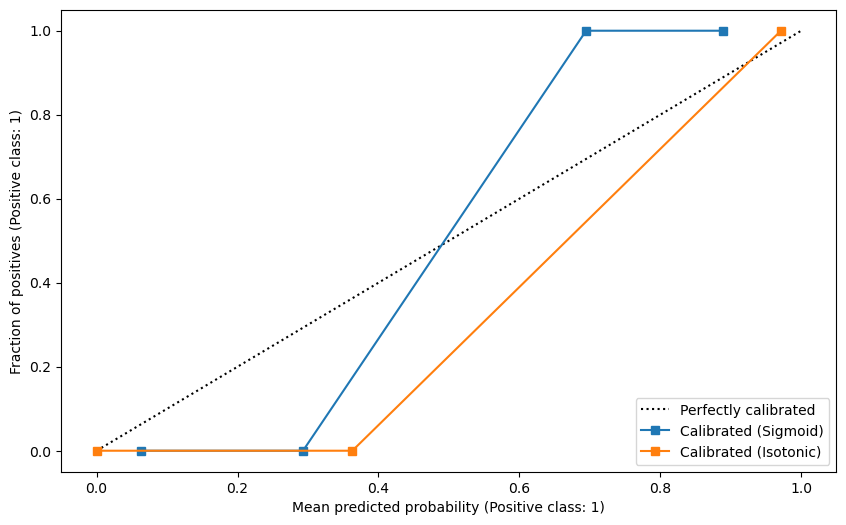

In [90]:
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))

for name, model in models.items():
    probs = model.predict_proba(X_test)[:, 1]
    brier = brier_score_loss(y_test, probs)
    print(f"{name}: Brier Score = {brier:.4f}")
    
    CalibrationDisplay.from_estimator(
        model, 
        X_test,
        y_test,
        name=name,
        ax=plt.gca())

**Задание:**
1. Обучить несколько моделей, с разной величиной отступа (гиперпараметр C).
2. Отобразить на графике, как менялась ширина разделяющей полосы для разных значений C. 

In [91]:
C_values = [0.01, 0.1, 1, 10, 100]
fig = make_subplots(
    rows=1, cols=len(C_values),
    subplot_titles=[f'C = {C}' for C in C_values],
    horizontal_spacing=0.05)
h = 0.02
x_min, x_max = X_train.iloc[:, 0].min() - 1, X_train.iloc[:, 0].max() + 1
y_min, y_max = X_train.iloc[:, 1].min() - 1, X_train.iloc[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

In [94]:
for i, C in enumerate(C_values):
    col = i + 1
    base_model = svm.LinearSVC(C=C, penalty='l2', random_state=0, dual=False, max_iter=10000)
    model = CalibratedClassifierCV(base_model, method='sigmoid', cv=5)
    model.fit(X_train, y_train)
    trained_classifiers = model.calibrated_classifiers_
    classifier = trained_classifiers[0].estimator

    w = classifier.coef_[0]
    margin = 2 / np.linalg.norm(w)
    
    fig.layout.annotations[i].update(text=f'C = {C}<br>Margin = {margin:.2f}')
    test_df = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=X_train.columns)
    Z = classifier.decision_function(test_df).reshape(xx.shape)
    fig.add_trace(
        go.Contour(
            z=Z,
            x=test_df[X_train.columns[0]].values.reshape(xx.shape)[0],
            y=test_df[X_train.columns[1]].values.reshape(xx.shape)[:, 0],
            colorscale='RdYlGn',
            line_width=2,
            contours=dict(
                start=-1,
                end=1,
                size=1,
                coloring='lines',
                showlabels=True,
                labelfont=dict(size=12, color='Black')),showscale=False),row=1, col=col)
    fig.add_trace(
        go.Scatter(
            x=X_train[X_train.columns[0]],
            y=X_train[X_train.columns[1]],
            mode='markers',
            marker=dict(
                size=10,
                color=y_train,
                line=dict(width=1, color='Black')),showlegend=False),row=1, col=col)
    support_vectors = np.where(np.abs(classifier.decision_function(X_train)) <= 1 + 1e-15)[0]
    fig.add_trace(
        go.Scatter(
            x=X_train.iloc[support_vectors][X_train.columns[0]],
            y=X_train.iloc[support_vectors][X_train.columns[1]],
            mode='markers',
            marker=dict(
                size=20,
                color=y_train.iloc[support_vectors],
                line=dict(width=1),
                symbol=[114] * len(support_vectors)),showlegend=False),row=1, col=col)

fig.update_layout(title_text='Влияние гиперпараметра C на ширину разделяющей полосы')
fig.update_xaxes(title_text='sepal length (cm)', row=1, col=1)
fig.update_yaxes(title_text='sepal width (cm)', row=1, col=1)

for i in range(2, len(C_values) + 1):
    fig.update_xaxes(title_text='', row=1, col=i)
    fig.update_yaxes(title_text='', row=1, col=i)

fig.show()